In [1]:
import anndata as ad

st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/trainsets/syndri_predictions/chromium_breast_train_with_admix_probs.h5ad')
# sc_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/split_sc_ref/breast_cancer_chromium.h5ad')

In [2]:
st_data

AnnData object with n_obs × n_vars = 85819 × 277
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample_id', 'percent_mt', 'percent_ribo', 'percent_hb', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'SCT_snn_res.0.5', 'SCT_snn_res.0.4', 'SCT_snn_res.2', 'donor_id', 'nCount_SoupX', 'nFeature_SoupX', 'Harmonised_Level4', 'Level3', 'Level2', 'Level1', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'input_material', 'histology', 'sample_type', 'histology_immune', 'DV200_percent', 'block_age_months', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'batch', 'source_sc_id', 'sampled_sc_id', 'matched_st_id', 'matched_st_index', 'selected_match_idx', 'x_centroid', 'y_centroid',

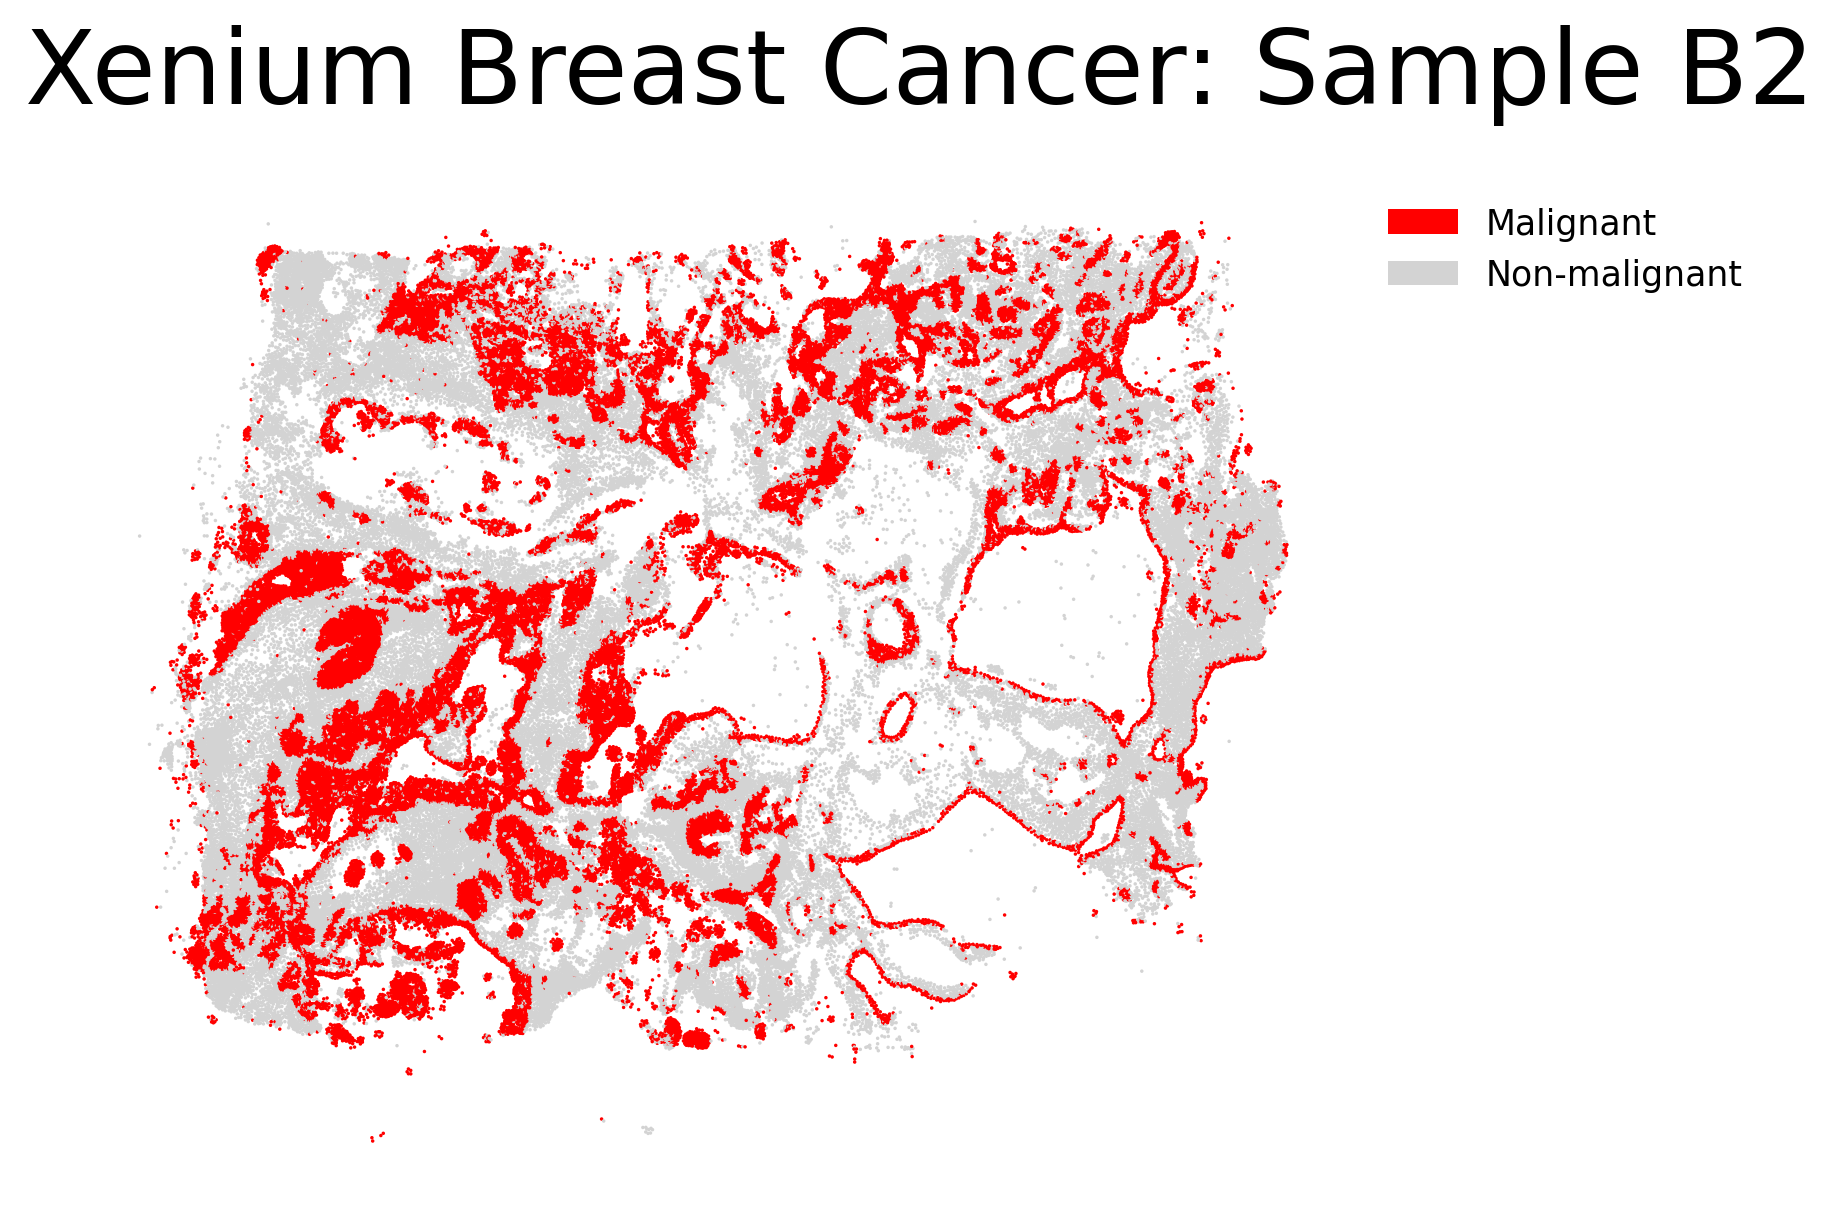

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

is_malignant = st_data.obs["harmony_cell_type"].str.contains(
    "malignant cell",
    case=False,
    na=False,
)

fig, ax = plt.subplots(figsize=(7, 7 * (35 / 50)), dpi=250)

sns.scatterplot(
    data=st_data.obs,
    x="x_centroid",
    y="y_centroid",
    hue=is_malignant,
    s=1,
    legend=False,
    palette={
        False: "lightgray",
        True: "red",
    },
    linewidth=0,
    ax=ax,
)

legend_handles = [
    Patch(facecolor="red", edgecolor="none", label="Malignant"),
    Patch(facecolor="lightgray", edgecolor="none", label="Non-malignant"),
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False,
    fontsize=10,
)

ax.axis("off")

# ax.set_ylim([200, 5500])
# ax.set_xlim([0, 6900])

fig.suptitle(
    "Xenium Breast Cancer: Sample B2",
    fontsize=30,
)

fig.tight_layout()

In [ ]:
st_data = st_data[st_data.obs['harmony_cell_type'].str.contains('T')]

# st_data = st_data[st_data.obs.groupby('cell_type').sample(frac=0.1).index]

In [ ]:
# st_data.layers['split_purified_counts_X']
# st_data.X

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
split_deltas =  (st_data.layers['split_purified_counts_trial_0'] - st_data.layers['trial_0'] ).toarray().ravel() #/ (st_data.layers['trial_0'].toarray().ravel()+np.finfo(float).eps)

syndri_probs = st_data.layers['admix_probs_trial_0'].toarray().ravel()

fig,ax = plt.subplots(figsize=(7,5),dpi=250)
sns.scatterplot(x=syndri_probs,y=split_deltas,s=1,ax=ax,alpha=0.05)
ax.set_xlabel('Syndri Probabilities')
ax.set_ylabel('SPLIT - Raw Counts')
ax.set_title('Xenium Breast Cancer B1_3: Syndri Probs vs SPLIT Deltas')
# sns.kdeplot(x=syndri_probs,y=split_deltas, levels=5, color="blue", linewidths=1.5,ax=ax)


Fraction of matrix expressed: 0.09067875748737068
Fraction of expressed entries with probability exactly zero: 0.0
Expressed-entry mean: 0.117603734
Expressed-entry std: 0.2634233
Expressed-entry quantiles: [1.28182901e-05 1.13343924e-04 5.33621537e-04 1.81198720e-03
 1.09710675e-02 6.44332692e-02 3.66884667e-01 9.99984622e-01
 9.99999881e-01]
Nonzero probabilities assigned to unexpressed genes: 0.0


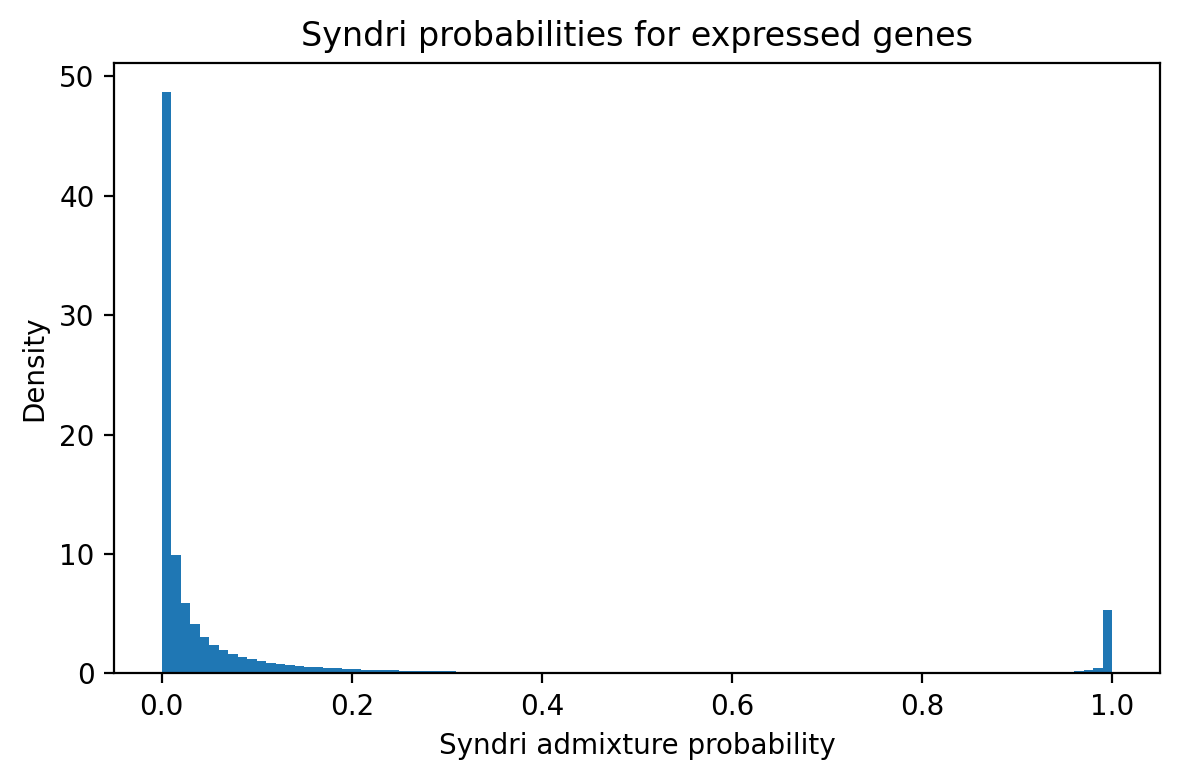

In [3]:
import numpy as np

prob_matrix = st_data.layers["admix_probs"].toarray()
raw_matrix = st_data.X.toarray() + st_data.layers['admixed_counts'].toarray()

expressed_mask = raw_matrix > 0
expressed_probs = prob_matrix[expressed_mask]

print("Fraction of matrix expressed:", expressed_mask.mean())
print(
    "Fraction of expressed entries with probability exactly zero:",
    np.mean(expressed_probs == 0),
)

print("Expressed-entry mean:", expressed_probs.mean())
print("Expressed-entry std:", expressed_probs.std())
print(
    "Expressed-entry quantiles:",
    np.quantile(
        expressed_probs,
        [0, 0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1],
    ),
)

print(
    "Nonzero probabilities assigned to unexpressed genes:",
    np.mean(prob_matrix[~expressed_mask] > 0),
)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4), dpi=200)

ax.hist(
    expressed_probs,
    bins=100,
    density=True,
)

ax.set_xlabel("Syndri admixture probability")
ax.set_ylabel("Density")
ax.set_title("Syndri probabilities for expressed genes")

plt.tight_layout()
plt.show()

In [4]:
masked_probs = np.where(
    expressed_mask,
    prob_matrix,
    np.nan,
)

mean_by_cell = np.nanmean(masked_probs, axis=1)
mean_by_gene = np.nanmean(masked_probs, axis=0)

print("Mean expressed-entry probability:", np.nanmean(masked_probs))
print("Cell-mean SD:", np.nanstd(mean_by_cell))
print("Gene-mean SD:", np.nanstd(mean_by_gene))
y = prob_matrix[expressed_mask]
overall_mean = y.mean()

# Gene-only prediction: assign each observation its gene's average probability
gene_prediction_matrix = np.broadcast_to(
    mean_by_gene[None, :],
    prob_matrix.shape,
)

gene_predictions = gene_prediction_matrix[expressed_mask]

gene_only_r2 = 1 - (
    np.sum((y - gene_predictions) ** 2)
    / np.sum((y - overall_mean) ** 2)
)

# Cell-only prediction
cell_prediction_matrix = np.broadcast_to(
    mean_by_cell[:, None],
    prob_matrix.shape,
)

cell_predictions = cell_prediction_matrix[expressed_mask]

cell_only_r2 = 1 - (
    np.sum((y - cell_predictions) ** 2)
    / np.sum((y - overall_mean) ** 2)
)

print(f"Variation explained by gene identity: {gene_only_r2:.3f}")
print(f"Variation explained by cell identity: {cell_only_r2:.3f}")


/tmp/ipykernel_2346946/618994333.py:8: RuntimeWarning: Mean of empty slice
  mean_by_gene = np.nanmean(masked_probs, axis=0)


Mean expressed-entry probability: 0.11760381
Cell-mean SD: 0.050672784
Gene-mean SD: 0.09030576
Variation explained by gene identity: 0.049
Variation explained by cell identity: 0.050


In [5]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

k = 3
cell_type_col = "cell_type"

coords = st_data.obs[["x_centroid","y_centroid"]].values
cell_types = st_data.obs[cell_type_col].astype(str)

neighbor_model = NearestNeighbors(
    n_neighbors=k + 1,
    metric="euclidean",
)

neighbor_indices = (
    neighbor_model
    .fit(coords)
    .kneighbors(return_distance=False)
)

# Remove each cell itself
neighbor_indices = neighbor_indices[:, 1:]

neighbor_types = cell_types.to_numpy()[neighbor_indices]

neighbor_categories = sorted(cell_types.dropna().unique())

neighbor_composition = pd.DataFrame(
    {
        f"neighbor_prop__{category}":
        (neighbor_types == category).mean(axis=1)
        for category in neighbor_categories
    },
    index=st_data.obs_names,
)

neighbor_composition.head()

,"neighbor_prop__CD4-positive, alpha-beta memory T cell",neighbor_prop__capillary endothelial cell,neighbor_prop__classical monocyte,neighbor_prop__cytotoxic T cell,neighbor_prop__fibroblast of breast,neighbor_prop__fibroblast of lung,neighbor_prop__macrophage,neighbor_prop__malignant cell,neighbor_prop__mast cell,neighbor_prop__natural T-regulatory cell,neighbor_prop__natural killer cell,neighbor_prop__pericyte,neighbor_prop__plasma cell,neighbor_prop__plasmacytoid dendritic cell,neighbor_prop__smooth muscle cell
GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1,0.0,0.0,0.333333,0.0,0.0,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
GSM9509174_breast_breast_B1_B1_3:aaabdcfd-1,0.0,0.0,0.333333,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.333333,0.333333
GSM9509174_breast_breast_B1_B1_3:aaablalj-1,0.0,0.0,0.000000,0.0,0.0,0.333333,0.0,0.666667,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
GSM9509174_breast_breast_B1_B1_3:aaacfdmo-1,0.0,0.0,0.000000,0.0,0.0,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.333333
GSM9509174_breast_breast_B1_B1_3:aaacnbab-1,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000


In [6]:
import scipy.sparse as sp

raw_layer = st_data.X + st_data.layers["admixed_counts"]
prob_layer = st_data.layers["admix_probs"]

raw_coo = sp.coo_matrix(raw_layer)
prob_csr = sp.csr_matrix(prob_layer)

# One row for every expressed cell-gene observation
cell_indices = raw_coo.row
gene_indices = raw_coo.col
raw_counts = raw_coo.data

syndri_scores = np.asarray(
    prob_csr[cell_indices, gene_indices]
).ravel()

evaluation_df = pd.DataFrame({
    "cell_index": cell_indices,
    "gene_index": gene_indices,
    "cell_id": st_data.obs_names[cell_indices],
    "gene": st_data.var_names[gene_indices],
    "raw_count": raw_counts,
    "syndri_score": syndri_scores,
})

evaluation_df["central_cell_type"] = (
    st_data.obs[cell_type_col]
    .astype(str)
    .to_numpy()[cell_indices]
)

if "sample_replicate" in st_data.obs:
    evaluation_df["sample_replicate"] = (
        st_data.obs["sample_replicate"]
        .astype(str)
        .to_numpy()[cell_indices]
    )
else:
    evaluation_df["sample_replicate"] = "single_sample"

# Logit-transform the scores
epsilon = 1e-5

p = evaluation_df["syndri_score"].clip(
    epsilon,
    1 - epsilon,
)

evaluation_df["syndri_logit"] = np.log(
    p / (1 - p)
)

# Attach each cell's neighborhood composition
evaluation_df = evaluation_df.join(
    neighbor_composition,
    on="cell_id",
)

evaluation_df.head()

,cell_index,gene_index,cell_id,gene,raw_count,syndri_score,central_cell_type,sample_replicate,syndri_logit,"neighbor_prop__CD4-positive, alpha-beta memory T cell",...,neighbor_prop__fibroblast of lung,neighbor_prop__macrophage,neighbor_prop__malignant cell,neighbor_prop__mast cell,neighbor_prop__natural T-regulatory cell,neighbor_prop__natural killer cell,neighbor_prop__pericyte,neighbor_prop__plasma cell,neighbor_prop__plasmacytoid dendritic cell,neighbor_prop__smooth muscle cell
0,0,3,GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1,ENSG00000168615,1.0,0.000532,macrophage,single_sample,-7.538266,0.0,...,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,13,GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1,ENSG00000148513,88.0,0.999534,macrophage,single_sample,7.671650,0.0,...,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,16,GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1,ENSG00000130208,3.0,0.001252,macrophage,single_sample,-6.682051,0.0,...,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,25,GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1,ENSG00000173372,5.0,0.000269,macrophage,single_sample,-8.221767,0.0,...,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,26,GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1,ENSG00000159189,9.0,0.000149,macrophage,single_sample,-8.810893,0.0,...,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Optional subsampling for computational tractability
max_rows = 1_000_000

if len(evaluation_df) > max_rows:
    model_df = evaluation_df.sample(
        max_rows,
        random_state=42,
    ).copy()
else:
    model_df = evaluation_df.copy()

neighbor_columns = [
    column
    for column in model_df.columns
    if column.startswith("neighbor_prop__")
]

baseline_categorical = [
    "gene",
    "central_cell_type",
    "sample_replicate",
]

baseline_numeric = [
    "raw_count",
]

full_numeric = baseline_numeric + neighbor_columns

baseline_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
            ),
            baseline_categorical,
        ),
        (
            "numeric",
            StandardScaler(),
            baseline_numeric,
        ),
    ],
)

full_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
            ),
            baseline_categorical,
        ),
        (
            "numeric",
            StandardScaler(),
            full_numeric,
        ),
    ],
)

baseline_model = make_pipeline(
    baseline_preprocessor,
    Ridge(alpha=10.0),
)

full_model = make_pipeline(
    full_preprocessor,
    Ridge(alpha=10.0),
)

X_baseline = model_df[
    baseline_categorical + baseline_numeric
]

X_full = model_df[
    baseline_categorical + full_numeric
]

y = model_df["syndri_logit"].to_numpy()

# Keep all rows from the same cell in the same fold
groups = model_df["cell_id"].to_numpy()

cv = GroupKFold(n_splits=5)

baseline_r2 = []
full_r2 = []

for train_idx, test_idx in cv.split(
    model_df,
    y,
    groups=groups,
):
    baseline_model.fit(
        X_baseline.iloc[train_idx],
        y[train_idx],
    )

    baseline_prediction = baseline_model.predict(
        X_baseline.iloc[test_idx]
    )

    full_model.fit(
        X_full.iloc[train_idx],
        y[train_idx],
    )

    full_prediction = full_model.predict(
        X_full.iloc[test_idx]
    )

    baseline_r2.append(
        r2_score(
            y[test_idx],
            baseline_prediction,
        )
    )

    full_r2.append(
        r2_score(
            y[test_idx],
            full_prediction,
        )
    )

baseline_mean = np.mean(baseline_r2)
full_mean = np.mean(full_r2)
neighbor_delta = full_mean - baseline_mean

print(f"Baseline cross-validated R²: {baseline_mean:.3f}")
print(f"Full cross-validated R²:     {full_mean:.3f}")
print(f"Additional neighbor R²:      {neighbor_delta:.3f}")

Baseline cross-validated R²: 0.129
Full cross-validated R²:     0.130
Additional neighbor R²:      0.001


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Extract values
# ------------------------------------------------------------
raw_counts = st_data.layers["trial_0"].toarray().ravel()

split_counts = (
    st_data.layers["split_purified_counts_trial_0"]
    .toarray()
    .ravel()
)

syndri_probs = (
    st_data.layers["admix_probs_trial_0"]
    .toarray()
    .ravel()
)

# Positive values are easier to interpret than SPLIT - raw
counts_removed = raw_counts - split_counts

# Remove invalid observations
valid = (
    np.isfinite(syndri_probs)
    & np.isfinite(counts_removed)
    & (counts_removed >= 0)
)

# Optional but usually recommended:
# compare only gene-cell observations with at least one input count
valid &= raw_counts > 0

comparison_df = pd.DataFrame({
    "syndri_probability": syndri_probs[valid],
    "split_counts_removed": counts_removed[valid],
})


# ------------------------------------------------------------
# Bin Syndri probabilities
# ------------------------------------------------------------
comparison_df = pd.DataFrame({
    "syndri_probability": syndri_probs[valid],
    "raw_counts": raw_counts[valid],
    "split_counts": split_counts[valid],
    "split_counts_removed": counts_removed[valid],
})

comparison_df["fraction_removed"] = (
    comparison_df["split_counts_removed"]
    / comparison_df["raw_counts"]
).clip(0, 1)

# Whether SPLIT removed the entire observed count
comparison_df["completely_removed"] = np.isclose(
    comparison_df["split_counts"],
    0,
)

probability_edges = np.linspace(0, 1, 11)

comparison_df["probability_bin"] = pd.cut(
    comparison_df["syndri_probability"],
    bins=probability_edges,
    include_lowest=True,
)

bin_summary = (
    comparison_df
    .groupby("probability_bin", observed=True)
    .agg(
        mean_probability=("syndri_probability", "mean"),
        mean_fraction_removed=("fraction_removed", "mean"),
        median_fraction_removed=("fraction_removed", "median"),
        q25_fraction_removed=(
            "fraction_removed",
            lambda x: x.quantile(0.25),
        ),
        q75_fraction_removed=(
            "fraction_removed",
            lambda x: x.quantile(0.75),
        ),
        fraction_completely_removed=("completely_removed", "mean"),
        mean_counts_removed=("split_counts_removed", "mean"),
        n_observations=("split_counts_removed", "size"),
    )
    .reset_index()
)

bin_summary["probability_midpoint"] = (
    bin_summary["probability_bin"]
    .map(lambda interval: interval.mid)
    .astype(float)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    dpi=250,
)

# Panel 1: density of individual gene-cell observations
hexbin = axes[0].hexbin(
    comparison_df["syndri_probability"],
    comparison_df["split_counts_removed"],
    gridsize=(60, 40),
    bins="log",
    mincnt=1,
    cmap="viridis",
)

colorbar = fig.colorbar(
    hexbin,
    ax=axes[0],
)

colorbar.set_label("log10 number of observations")

axes[0].set_xlabel("Syndri admixture probability")
axes[0].set_ylabel("Counts removed by SPLIT")
axes[0].set_title("Gene-level agreement")

# Optional: prevent rare extreme removals from compressing the plot
upper_limit = comparison_df["split_counts_removed"].quantile(0.995)
axes[0].set_ylim(-0.5, upper_limit)


# Panel 2: conditional probability of SPLIT removing counts
x = bin_summary["probability_midpoint"]
y = bin_summary["mean_fraction_removed"]

axes[1].plot(
    x,
    y,
    marker="o",
    label="Mean fraction removed",
)

axes[1].fill_between(
    x,
    bin_summary["q25_fraction_removed"],
    bin_summary["q75_fraction_removed"],
    alpha=0.2,
    label="Interquartile range",
)

axes[1].set_xlabel("Syndri admixture probability")
axes[1].set_ylabel("Fraction of observed counts removed by SPLIT")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_title("SPLIT removal magnitude by Syndri probability")
axes[1].legend(frameon=False)

fig.suptitle(
    "Xenium Breast Cancer B1_3: Syndri versus SPLIT",
    fontsize=16,
)

fig.tight_layout()
plt.show()

display(bin_summary)